In [1]:
import io
import zipfile
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_colwidth", 120)

In [2]:
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

with urllib.request.urlopen(url) as response:
    archive_bytes = response.read()

with zipfile.ZipFile(io.BytesIO(archive_bytes)) as z:
    # The original file is tab-separated and has no header.
    with z.open("SMSSpamCollection") as f:
        df = pd.read_csv(
            f,
            sep="\\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

# Save a normal comma-separated CSV for future use.
df.to_csv("sms_spam.csv", index=False)

print("Dataset shape:", df.shape)
print("CSV saved as sms_spam.csv")
df.head(10)

Dataset shape: (5574, 2)
CSV saved as sms_spam.csv


/tmp/ipykernel_56791/2931499056.py:9: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...
6,ham,Even my brother is not like to speak with me. They treat me like aids patent.
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Calle...
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906170146...
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call Th...


In [3]:
print(df.info())
print("\\nMissing values:")
print(df.isna().sum())
print("\\nClass counts:")
print(df["label"].value_counts())
print("\\nClass percentages:")
print(df["label"].value_counts(normalize=True).mul(100).round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5574 non-null   object
 1   message  5574 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
\nMissing values:
label      0
message    0
dtype: int64
\nClass counts:
label
ham     4827
spam     747
Name: count, dtype: int64
\nClass percentages:
label
ham     86.6
spam    13.4
Name: proportion, dtype: float64


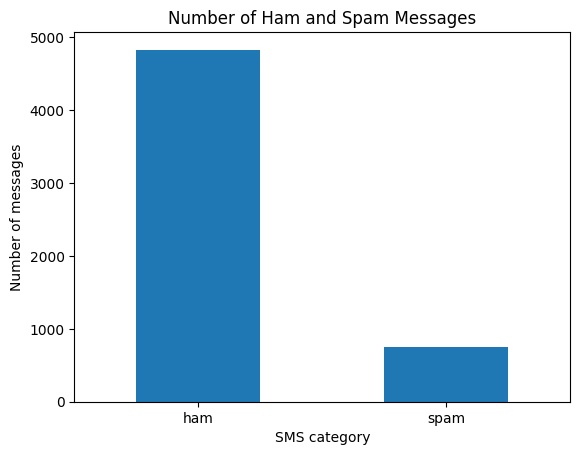

In [4]:
ax = df["label"].value_counts().plot(kind="bar", rot=0)
ax.set_title("Number of Ham and Spam Messages")
ax.set_xlabel("SMS category")
ax.set_ylabel("Number of messages")
plt.show()

In [6]:
x = df["message"]
y = df["label"]

print("X Example:")
print(x.iloc[0])
print("\ny example:")
print(y.iloc[0])

X Example:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

y example:
ham
